All cells are stand-alone. Future iteration should fix the code redundancy.

# Prep Data

In [ ]:
import json
import glob
import pandas as pd

ALL_SYMPTOMS = [
    "1. Sadness", "2. Pessimism", "3. Past Failure", "4. Loss of Pleasure",
    "5. Guilty Feelings", "6. Punishment Feelings", "7. Self-Dislike",
    "8. Self-Criticalness", "9. Suicidal Thoughts or Wishes", "10. Crying",
    "11. Agitation", "12. Loss of Interest", "13. Indecisiveness",
    "14. Worthlessness", "15. Loss of Energy", "16. Changes in Sleeping Pattern",
    "17. Irritability", "18. Changes in Appetite", "19. Concentration Difficulty",
    "20. Tiredness or Fatigue", "21. Loss of Interest in Sex"
]

# Items 16 and 18 use a 7-option response scale (0,1a,1b,2a,2b,3a,3b),
# stored as integers 0-6. Map back to BDI-II standard 0-3.
SPLIT_ITEMS = {
    "16. Changes in Sleeping Pattern",
    "18. Changes in Appetite",
}
SPLIT_ITEM_REMAP = {0: 0, 1: 1, 2: 1, 3: 2, 4: 2, 5: 3, 6: 3}

# ---- Prolific ID -> Clinician ID mapping ----
# mapping_df = pd.read_csv("private-prolific_id_mapping.csv")
# prolific_to_clinician = dict(
#     zip(mapping_df["ProlificId"].astype(str), mapping_df["ClinicianId"])
# )

json_files = glob.glob("*.json")  # or "/content/*.json"

rows = []

for filepath in json_files:
    with open(filepath, "r") as f:
        data = json.load(f)

    turn_annots = {ann["turn"]: ann for ann in data.get("turn_annotations", [])}

    turn_number = 0
    i = 0
    messages = [m for m in data["messages"] if m["role"] != "system"]

    while i < len(messages):
        msg = messages[i]

        if msg["role"] == "user":
            turn_number += 1
            if i + 1 < len(messages) and messages[i + 1]["role"] == "assistant":
                assistant_msg = messages[i + 1]
                i += 2
            else:
                # No assistant reply — skip turn, but counter already incremented
                i += 1
                continue
        else:
            i += 1
            continue

        annot = turn_annots.get(turn_number, {})  # empty dict instead of skip
        annotated_symptoms = set(annot.get("symptoms", []))
        scores_dict = annot.get("scores", {})

        # prolific_id = str(data.get("prolific_id", ""))
        # clinician_id = prolific_to_clinician.get(prolific_id, None)

        row = {
            "session_id": data.get("session_id", ""),
            "persona_id": data.get("persona_id", ""),
            "clinician_id": data.get("clinician_id", ""),
            "turn": turn_number,
            "Message": msg["content"],
            "PersonaReply": assistant_msg["content"],
        }

        for sym in ALL_SYMPTOMS:
            row[sym] = 1 if sym in annotated_symptoms else 0

        for sym in ALL_SYMPTOMS:
            sym_num = sym.split(".")[0]
            col_name = f"{sym_num}.Score"
            score = int(scores_dict[sym]["score"]) if sym in scores_dict else -1

            # Remap items 16 and 18 from the 7-point split scale back to 0-3
            if sym in SPLIT_ITEMS and score != -1:
                score = SPLIT_ITEM_REMAP.get(score, score)

            row[col_name] = score

        rows.append(row)

df = pd.DataFrame(rows)

meta_cols = ["persona_id", "clinician_id", "turn"]
score_cols = [f"{sym.split('.')[0]}.Score" for sym in ALL_SYMPTOMS]
df = df[meta_cols + ["Message", "PersonaReply"] + ALL_SYMPTOMS + score_cols]

# session_id is dropped (not included in meta_cols above), so the final
# CSV never contains it.

df.to_csv("bdichat_turn_annotations.csv", index=False)
print(f"Saved {len(df)} rows to bdichat_turn_annotations.csv")

Saved 2332 rows to bdichat_turn_annotations.csv


# Split

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# Load base data
df_base = pd.read_csv("bdichat_turn_annotations.csv")
df_base = df_base.dropna(subset=["PersonaReply"]).reset_index(drop=True)
df_base["Message"] = df_base["Message"].fillna("")

# Single shared split — used by ALL methods
train_idx, test_idx = train_test_split(
    np.arange(len(df_base)), test_size=0.3, random_state=42
)
print(f"Total: {len(df_base)} | Train: {len(train_idx)} | Test: {len(test_idx)}")

# Save test indices so any cell can reference them
np.save("test_idx.npy", test_idx)
np.save("train_idx.npy", train_idx)

Total: 2332 | Train: 1632 | Test: 700


#GPT

### With Item Names

In [ ]:
from google.colab import userdata
import os, json, time
import pandas as pd
from openai import OpenAI
from tqdm import tqdm

os.environ["OPENAI_API_KEY"] = userdata.get('OPENAI_API_KEY')
client = OpenAI(api_key=os.environ["OPENAI_API_KEY"])

SYMPTOMS = {
    1: "Sadness", 2: "Pessimism", 3: "Past Failure", 4: "Loss of Pleasure",
    5: "Guilty Feelings", 6: "Punishment Feelings", 7: "Self-Dislike",
    8: "Self-Criticalness", 9: "Suicidal Thoughts or Wishes", 10: "Crying",
    11: "Agitation", 12: "Loss of Interest", 13: "Indecisiveness",
    14: "Worthlessness", 15: "Loss of Energy", 16: "Changes in Sleeping Pattern",
    17: "Irritability", 18: "Changes in Appetite", 19: "Concentration Difficulty",
    20: "Tiredness or Fatigue", 21: "Loss of Interest in Sex",
}

SYMPTOM_LIST_TEXT = "\n".join(f"{i}. {name}" for i, name in SYMPTOMS.items())

# Prompt
def format_relevance_prompt(clinician_msg: str, patient_reply: str) -> str:
    return f"""You are a clinical language analysis assistant trained on the Beck Depression Inventory-II (BDI-II).

Below are the 21 BDI-II symptom categories:

{SYMPTOM_LIST_TEXT}

---

The following is a conversational exchange between a clinician and a patient:

Clinician: "{clinician_msg}"
Patient: "{patient_reply}"

Your task:
Based on the patient's reply (and the clinician's question for context), identify which BDI-II symptom categories (if any) are clearly reflected. Only include items where there is direct, clear evidence in the patient's words.

Respond in JSON only — no extra text:
{{
  "item_numbers": [<list of integers from 1–21, or empty list if none apply>]
}}
"""

# API Call
def call_gpt_relevance(clinician_msg: str, patient_reply: str,
                       model: str = "gpt-4o-mini", max_retries: int = 3) -> str:
    wait = 5
    for attempt in range(max_retries):
        try:
            completion = client.chat.completions.create(
                model=model,
                messages=[{"role": "user", "content": format_relevance_prompt(clinician_msg, patient_reply)}],
                max_completion_tokens=200,
                response_format={"type": "json_object"},
            )
            return completion.choices[0].message.content.strip()
        except Exception as e:
            print(f"  Warning (attempt {attempt+1}/{max_retries}): {str(e)[:100]}")
            if attempt < max_retries - 1:
                time.sleep(wait)
                wait *= 2
            else:
                return f"[ERROR: {str(e)[:100]}]"


df = pd.read_csv("bdichat_turn_annotations.csv")
df = df.dropna(subset=["PersonaReply"]).reset_index(drop=True)
df["Message"] = df["Message"].fillna("")
# df = df.head(100)
print(f"Loaded {len(df)} rows.")

raw_outputs = []
for _, row in tqdm(df.iterrows(), total=len(df), desc="GPT relevance detection"):
    raw_outputs.append(call_gpt_relevance(row["Message"], row["PersonaReply"]))

df["raw_output"] = raw_outputs

# Parse Output to Binary Pred Columns
for i in range(1, 22):
    df[f"pred_label_{i}"] = 0

parse_errors = 0
for row_idx, raw in enumerate(raw_outputs):
    if raw.startswith("[ERROR"):
        parse_errors += 1
        continue
    try:
        parsed = json.loads(raw)
        for item_num in parsed.get("item_numbers", []):
            item_num = int(item_num)
            if 1 <= item_num <= 21:
                df.at[row_idx, f"pred_label_{item_num}"] = 1
    except (json.JSONDecodeError, ValueError, TypeError):
        parse_errors += 1

print(f"\nParse errors: {parse_errors} / {len(df)}")

df.to_csv("bdi_rel_pred_names.csv", index=False)
print("Saved → bdi_rel_pred_names.csv")

# Evaluate against ground truth
from sklearn.metrics import (
    classification_report, f1_score, precision_score, recall_score
)
import numpy as np

SYMPTOM_COLS = [f"{i}. {SYMPTOMS[i]}" for i in range(1, 22)]
PRED_COLS    = [f"pred_label_{i}" for i in range(1, 22)]
LABEL_NAMES  = list(SYMPTOMS.values())

y_true = df[SYMPTOM_COLS].values.astype(int)
y_pred = df[PRED_COLS].values.astype(int)

print("\n" + "="*70)
print("PER-LABEL CLASSIFICATION REPORT")
print("="*70)
print(classification_report(y_true, y_pred, target_names=LABEL_NAMES, zero_division=0, digits=3))

metrics = {
    "F1 macro"       : f1_score(y_true, y_pred, average="macro",    zero_division=0),
    "F1 micro"       : f1_score(y_true, y_pred, average="micro",    zero_division=0),
    "F1 weighted"    : f1_score(y_true, y_pred, average="weighted", zero_division=0),
    "Precision micro": precision_score(y_true, y_pred, average="micro", zero_division=0),
    "Recall micro"   : recall_score(y_true, y_pred, average="micro",    zero_division=0),
}
print("="*70)
print("AGGREGATE METRICS")
print("="*70)
for name, val in metrics.items():
    print(f"  {name:<20} {val:.4f}")

per_label_f1 = f1_score(y_true, y_pred, average=None, zero_division=0)
per_label_p  = precision_score(y_true, y_pred, average=None, zero_division=0)
per_label_r  = recall_score(y_true, y_pred, average=None, zero_division=0)

eval_df = pd.DataFrame({
    "Item"     : list(range(1, 22)),
    "Label"    : LABEL_NAMES,
    "Support"  : y_true.sum(axis=0).astype(int),
    "Precision": per_label_p.round(3),
    "Recall"   : per_label_r.round(3),
    "F1"       : per_label_f1.round(3),
}).sort_values("F1", ascending=False).reset_index(drop=True)

print("\nPER-LABEL F1 (sorted)")
print(eval_df.to_string(index=False))

eval_df.to_csv("bdi_rel_pred_names_eval.csv", index=False)
print("\nSaved → bdi_rel_pred_names_eval.csv")

Loaded 2332 rows.


GPT relevance detection: 100%|██████████| 2332/2332 [26:06<00:00,  1.49it/s]


Parse errors: 0 / 2332
Saved → bdi_rel_pred_names.csv

PER-LABEL CLASSIFICATION REPORT
                             precision    recall  f1-score   support

                    Sadness      0.365     0.344     0.354       157
                  Pessimism      0.475     0.271     0.345       177
               Past Failure      0.263     0.514     0.348       148
           Loss of Pleasure      0.317     0.489     0.384       131
            Guilty Feelings      0.484     0.397     0.437       156
        Punishment Feelings      0.600     0.303     0.402       119
               Self-Dislike      0.246     0.434     0.314       129
          Self-Criticalness      0.377     0.308     0.339       195
Suicidal Thoughts or Wishes      0.517     0.535     0.526       114
                     Crying      0.639     0.585     0.611       106
                  Agitation      0.356     0.318     0.336       132
           Loss of Interest      0.190     0.496     0.275       141
             I

### With Full Test

# TODO: Add the BDI-II Survey text here with the format: 

BDI_II_SURVEY = """
1. [Item Name]:
0) [Text]
1) [Text]
2) [Text]
3) [Text]

2. [Item Name]:
0) [Text]
1) [Text]
2) [Text]
3) [Text]
...
"""

In this notebook it is removed due to copyright.

In [ ]:
BDI_II_SURVEY = ""

In [ ]:
from google.colab import userdata
import os, json, time
import pandas as pd
from openai import OpenAI
from tqdm import tqdm

os.environ["OPENAI_API_KEY"] = userdata.get('OPENAI_API_KEY')
client = OpenAI(api_key=os.environ["OPENAI_API_KEY"])

SYMPTOMS = {
    1: "Sadness", 2: "Pessimism", 3: "Past Failure", 4: "Loss of Pleasure",
    5: "Guilty Feelings", 6: "Punishment Feelings", 7: "Self-Dislike",
    8: "Self-Criticalness", 9: "Suicidal Thoughts or Wishes", 10: "Crying",
    11: "Agitation", 12: "Loss of Interest", 13: "Indecisiveness",
    14: "Worthlessness", 15: "Loss of Energy", 16: "Changes in Sleeping Pattern",
    17: "Irritability", 18: "Changes in Appetite", 19: "Concentration Difficulty",
    20: "Tiredness or Fatigue", 21: "Loss of Interest in Sex",
}

SYMPTOM_LIST_TEXT = "\n".join(f"{i}. {name}" for i, name in SYMPTOMS.items())

# Prompt
def format_relevance_prompt(clinician_msg: str, patient_reply: str) -> str:
    return f"""You are a clinical language analysis assistant trained on the Beck Depression Inventory-II (BDI-II).

Below are the 21 BDI-II symptom categories:

{BDI_II_SURVEY}

---

The following is a conversational exchange between a clinician and a patient:

Clinician: "{clinician_msg}"
Patient: "{patient_reply}"

Your task:
Based on the patient's reply (and the clinician's question for context), identify which BDI-II symptom categories (if any) are clearly reflected. Only include items where there is direct, clear evidence in the patient's words.

Respond in JSON only — no extra text:
{{
  "item_numbers": [<list of integers from 1–21, or empty list if none apply>]
}}
"""

# API Call
def call_gpt_relevance(clinician_msg: str, patient_reply: str,
                       model: str = "gpt-4o-mini", max_retries: int = 3) -> str:
    wait = 5
    for attempt in range(max_retries):
        try:
            completion = client.chat.completions.create(
                model=model,
                messages=[{"role": "user", "content": format_relevance_prompt(clinician_msg, patient_reply)}],
                max_completion_tokens=200,
                response_format={"type": "json_object"},
            )
            return completion.choices[0].message.content.strip()
        except Exception as e:
            print(f"  Warning (attempt {attempt+1}/{max_retries}): {str(e)[:100]}")
            if attempt < max_retries - 1:
                time.sleep(wait)
                wait *= 2
            else:
                return f"[ERROR: {str(e)[:100]}]"

df = pd.read_csv("bdichat_turn_annotations.csv")
df = df.dropna(subset=["PersonaReply"]).reset_index(drop=True)
df["Message"] = df["Message"].fillna("")
# df = df.head(100)
print(f"Loaded {len(df)} rows.")

raw_outputs = []
for _, row in tqdm(df.iterrows(), total=len(df), desc="GPT relevance detection"):
    raw_outputs.append(call_gpt_relevance(row["Message"], row["PersonaReply"]))

df["raw_output"] = raw_outputs

# Parse Output to Binary Pred Columns
for i in range(1, 22):
    df[f"pred_label_{i}"] = 0

parse_errors = 0
for row_idx, raw in enumerate(raw_outputs):
    if raw.startswith("[ERROR"):
        parse_errors += 1
        continue
    try:
        parsed = json.loads(raw)
        for item_num in parsed.get("item_numbers", []):
            item_num = int(item_num)
            if 1 <= item_num <= 21:
                df.at[row_idx, f"pred_label_{item_num}"] = 1
    except (json.JSONDecodeError, ValueError, TypeError):
        parse_errors += 1

print(f"\nParse errors: {parse_errors} / {len(df)}")

df.to_csv("bdi_rel_pred_text.csv", index=False)
print("Saved → bdi_rel_pred_text.csv")

# Evaluate against ground truth
from sklearn.metrics import (
    classification_report, f1_score, precision_score, recall_score
)
import numpy as np

SYMPTOM_COLS = [f"{i}. {SYMPTOMS[i]}" for i in range(1, 22)]
PRED_COLS    = [f"pred_label_{i}" for i in range(1, 22)]
LABEL_NAMES  = list(SYMPTOMS.values())

y_true = df[SYMPTOM_COLS].values.astype(int)
y_pred = df[PRED_COLS].values.astype(int)

print("\n" + "="*70)
print("PER-LABEL CLASSIFICATION REPORT")
print("="*70)
print(classification_report(y_true, y_pred, target_names=LABEL_NAMES, zero_division=0, digits=3))

metrics = {
    "F1 macro"       : f1_score(y_true, y_pred, average="macro",    zero_division=0),
    "F1 micro"       : f1_score(y_true, y_pred, average="micro",    zero_division=0),
    "F1 weighted"    : f1_score(y_true, y_pred, average="weighted", zero_division=0),
    "Precision micro": precision_score(y_true, y_pred, average="micro", zero_division=0),
    "Recall micro"   : recall_score(y_true, y_pred, average="micro",    zero_division=0),
}
print("="*70)
print("AGGREGATE METRICS")
print("="*70)
for name, val in metrics.items():
    print(f"  {name:<20} {val:.4f}")

per_label_f1 = f1_score(y_true, y_pred, average=None, zero_division=0)
per_label_p  = precision_score(y_true, y_pred, average=None, zero_division=0)
per_label_r  = recall_score(y_true, y_pred, average=None, zero_division=0)

eval_df = pd.DataFrame({
    "Item"     : list(range(1, 22)),
    "Label"    : LABEL_NAMES,
    "Support"  : y_true.sum(axis=0).astype(int),
    "Precision": per_label_p.round(3),
    "Recall"   : per_label_r.round(3),
    "F1"       : per_label_f1.round(3),
}).sort_values("F1", ascending=False).reset_index(drop=True)

print("\nPER-LABEL F1 (sorted)")
print(eval_df.to_string(index=False))

eval_df.to_csv("bdi_rel_pred_text_eval.csv", index=False)
print("\nSaved → bdi_rel_pred_text_eval.csv")

Loaded 2332 rows.


GPT relevance detection: 100%|██████████| 2332/2332 [26:27<00:00,  1.47it/s]



Parse errors: 0 / 2332
Saved → bdi_rel_pred_text.csv

PER-LABEL CLASSIFICATION REPORT
                             precision    recall  f1-score   support

                    Sadness      0.326     0.287     0.305       157
                  Pessimism      0.496     0.339     0.403       177
               Past Failure      0.285     0.514     0.366       148
           Loss of Pleasure      0.439     0.412     0.425       131
            Guilty Feelings      0.590     0.314     0.410       156
        Punishment Feelings      0.755     0.311     0.440       119
               Self-Dislike      0.434     0.279     0.340       129
          Self-Criticalness      0.435     0.256     0.323       195
Suicidal Thoughts or Wishes      0.696     0.561     0.621       114
                     Crying      0.709     0.689     0.699       106
                  Agitation      0.494     0.333     0.398       132
           Loss of Interest      0.269     0.433     0.332       141
             In

### With Item Descriptions

In [ ]:
BDI_ITEM_DESCRIPTIONS = {
    1:  ("Sadness",                    "This item measures Sadness. It assesses whether the individual feels sad, unhappy, or emotionally low, ranging from no sadness to unbearable unhappiness."),
    2:  ("Pessimism",                  "This item measures Pessimism. It evaluates the individual's outlook on the future and the presence of hopelessness, assessing whether the individual feels optimistic, discouraged, or hopeless about the future."),
    3:  ("Past Failure",               "This item measures the Sense of Failure. It assesses feelings of personal failure and self-worth, ranging from no sense of failure to feeling like a total failure as a person."),
    4:  ("Loss of Pleasure",           "This item measures Loss of Pleasure. It evaluates the individual's ability to derive enjoyment from activities they used to enjoy, ranging from full enjoyment to complete inability to get pleasure."),
    5:  ("Guilty Feelings",            "This item measures Guilty Feelings. It assesses the extent to which the individual feels guilty about things they have done or failed to do, ranging from no guilt to constant guilt."),
    6:  ("Punishment Feelings",        "This item measures the Sense of Punishment. It assesses feelings of being punished or expecting punishment, determining if the individual feels they might be punished or are being punished constantly."),
    7:  ("Self-Dislike",               "This item measures Self-Dislike. It evaluates how the individual feels about themselves, ranging from neutral self-perception to active dislike of oneself."),
    8:  ("Self-Criticalness",          "This item measures Self-Criticalness. It assesses the degree to which the individual criticizes or blames themselves, ranging from no self-criticism to blaming themselves for everything bad."),
    9:  ("Suicidal Thoughts or Wishes","This item measures Suicidal Thoughts or Wishes. It assesses thoughts about death or self-harm, ranging from no thoughts of killing oneself to active intent."),
    10: ("Crying",                     "This item measures Crying. It evaluates how often the individual cries compared to usual, ranging from no change to feeling unable to cry despite wanting to."),
    11: ("Agitation",                  "This item measures Agitation. It assesses restlessness or being wound up, ranging from no agitation to severe agitation requiring constant movement."),
    12: ("Loss of Interest",           "This item measures Loss of Interest. It evaluates interest in other people and activities, ranging from no loss of interest to extreme difficulty getting interested in anything."),
    13: ("Indecisiveness",             "This item measures Indecisiveness. It assesses the ability to make decisions, ranging from making decisions as well as ever to being unable to make any decision."),
    14: ("Worthlessness",              "This item measures Worthlessness. It evaluates the individual's sense of self-worth, ranging from not feeling worthless to feeling utterly worthless."),
    15: ("Loss of Energy",             "This item measures Loss of Energy. It assesses energy levels, ranging from having as much energy as ever to lacking energy to do anything."),
    16: ("Changes in Sleeping Pattern","This item measures Changes in Sleeping Pattern. It evaluates changes in sleep habits, including sleeping too much or too little compared to usual."),
    17: ("Irritability",               "This item measures Irritability. It assesses how irritable or easily annoyed the individual is, ranging from no change to being irritable all the time."),
    18: ("Changes in Appetite",        "This item measures Changes in Appetite. It evaluates changes in appetite or eating habits, including eating more or less than usual."),
    19: ("Concentration Difficulty",   "This item measures Concentration Difficulty. It assesses the ability to concentrate, ranging from concentrating as well as ever to being completely unable to concentrate."),
    20: ("Tiredness or Fatigue",       "This item measures Tiredness or Fatigue. It evaluates how tired or fatigued the individual is, ranging from no more tired than usual to too fatigued to do anything."),
    21: ("Loss of Interest in Sex",    "This item measures Loss of Interest in Sex. It assesses changes in sexual interest, ranging from no change to complete loss of interest in sex."),
}
SYMPTOM_DESC_TEXT = "\n".join(f"{i}. {name[0]}: {name[1]}" for i, name in BDI_ITEM_DESCRIPTIONS.items())


In [ ]:
from google.colab import userdata
import os, json, time
import pandas as pd
from openai import OpenAI
from tqdm import tqdm

os.environ["OPENAI_API_KEY"] = userdata.get('OPENAI_API_KEY')
client = OpenAI(api_key=os.environ["OPENAI_API_KEY"])

SYMPTOMS = {
    1: "Sadness", 2: "Pessimism", 3: "Past Failure", 4: "Loss of Pleasure",
    5: "Guilty Feelings", 6: "Punishment Feelings", 7: "Self-Dislike",
    8: "Self-Criticalness", 9: "Suicidal Thoughts or Wishes", 10: "Crying",
    11: "Agitation", 12: "Loss of Interest", 13: "Indecisiveness",
    14: "Worthlessness", 15: "Loss of Energy", 16: "Changes in Sleeping Pattern",
    17: "Irritability", 18: "Changes in Appetite", 19: "Concentration Difficulty",
    20: "Tiredness or Fatigue", 21: "Loss of Interest in Sex",
}

SYMPTOM_LIST_TEXT = "\n".join(f"{i}. {name}" for i, name in SYMPTOMS.items())

# Prompt
def format_relevance_prompt(clinician_msg: str, patient_reply: str) -> str:
    return f"""You are a clinical language analysis assistant trained on the Beck Depression Inventory-II (BDI-II).

Below are the 21 BDI-II symptom categories:

{SYMPTOM_DESC_TEXT}

---

The following is a conversational exchange between a clinician and a patient:

Clinician: "{clinician_msg}"
Patient: "{patient_reply}"

Your task:
Based on the patient's reply (and the clinician's question for context), identify which BDI-II symptom categories (if any) are clearly reflected. Only include items where there is direct, clear evidence in the patient's words.

Respond in JSON only — no extra text:
{{
  "item_numbers": [<list of integers from 1–21, or empty list if none apply>]
}}
"""

# API Call
def call_gpt_relevance(clinician_msg: str, patient_reply: str,
                       model: str = "gpt-4o-mini", max_retries: int = 3) -> str:
    wait = 5
    for attempt in range(max_retries):
        try:
            completion = client.chat.completions.create(
                model=model,
                messages=[{"role": "user", "content": format_relevance_prompt(clinician_msg, patient_reply)}],
                max_completion_tokens=200,
                response_format={"type": "json_object"},
            )
            return completion.choices[0].message.content.strip()
        except Exception as e:
            print(f"  Warning (attempt {attempt+1}/{max_retries}): {str(e)[:100]}")
            if attempt < max_retries - 1:
                time.sleep(wait)
                wait *= 2
            else:
                return f"[ERROR: {str(e)[:100]}]"

df = pd.read_csv("bdichat_turn_annotations.csv")
df = df.dropna(subset=["PersonaReply"]).reset_index(drop=True)
df["Message"] = df["Message"].fillna("")
# df = df.head(100)
print(f"Loaded {len(df)} rows.")

raw_outputs = []
for _, row in tqdm(df.iterrows(), total=len(df), desc="GPT relevance detection"):
    raw_outputs.append(call_gpt_relevance(row["Message"], row["PersonaReply"]))

df["raw_output"] = raw_outputs

# Parse Output to Binary Pred Columns
for i in range(1, 22):
    df[f"pred_label_{i}"] = 0

parse_errors = 0
for row_idx, raw in enumerate(raw_outputs):
    if raw.startswith("[ERROR"):
        parse_errors += 1
        continue
    try:
        parsed = json.loads(raw)
        for item_num in parsed.get("item_numbers", []):
            item_num = int(item_num)
            if 1 <= item_num <= 21:
                df.at[row_idx, f"pred_label_{item_num}"] = 1
    except (json.JSONDecodeError, ValueError, TypeError):
        parse_errors += 1

print(f"\nParse errors: {parse_errors} / {len(df)}")

df.to_csv("bdi_rel_pred_desc.csv", index=False)
print("Saved → bdi_rel_pred_desc.csv")

# Evaluate against ground truth
from sklearn.metrics import (
    classification_report, f1_score, precision_score, recall_score
)
import numpy as np

SYMPTOM_COLS = [f"{i}. {SYMPTOMS[i]}" for i in range(1, 22)]
PRED_COLS    = [f"pred_label_{i}" for i in range(1, 22)]
LABEL_NAMES  = list(SYMPTOMS.values())

y_true = df[SYMPTOM_COLS].values.astype(int)
y_pred = df[PRED_COLS].values.astype(int)

print("\n" + "="*70)
print("PER-LABEL CLASSIFICATION REPORT")
print("="*70)
print(classification_report(y_true, y_pred, target_names=LABEL_NAMES, zero_division=0, digits=3))

metrics = {
    "F1 macro"       : f1_score(y_true, y_pred, average="macro",    zero_division=0),
    "F1 micro"       : f1_score(y_true, y_pred, average="micro",    zero_division=0),
    "F1 weighted"    : f1_score(y_true, y_pred, average="weighted", zero_division=0),
    "Precision micro": precision_score(y_true, y_pred, average="micro", zero_division=0),
    "Recall micro"   : recall_score(y_true, y_pred, average="micro",    zero_division=0),
}
print("="*70)
print("AGGREGATE METRICS")
print("="*70)
for name, val in metrics.items():
    print(f"  {name:<20} {val:.4f}")

per_label_f1 = f1_score(y_true, y_pred, average=None, zero_division=0)
per_label_p  = precision_score(y_true, y_pred, average=None, zero_division=0)
per_label_r  = recall_score(y_true, y_pred, average=None, zero_division=0)

eval_df = pd.DataFrame({
    "Item"     : list(range(1, 22)),
    "Label"    : LABEL_NAMES,
    "Support"  : y_true.sum(axis=0).astype(int),
    "Precision": per_label_p.round(3),
    "Recall"   : per_label_r.round(3),
    "F1"       : per_label_f1.round(3),
}).sort_values("F1", ascending=False).reset_index(drop=True)

print("\nPER-LABEL F1 (sorted)")
print(eval_df.to_string(index=False))

eval_df.to_csv("bdi_rel_pred_desc_eval.csv", index=False)
print("\nSaved → bdi_rel_pred_desc_eval.csv")

Loaded 2332 rows.


GPT relevance detection: 100%|██████████| 2332/2332 [23:18<00:00,  1.67it/s]


Parse errors: 0 / 2332
Saved → bdi_rel_pred_desc.csv

PER-LABEL CLASSIFICATION REPORT
                             precision    recall  f1-score   support

                    Sadness      0.404     0.363     0.383       157
                  Pessimism      0.493     0.384     0.432       177
               Past Failure      0.243     0.608     0.347       148
           Loss of Pleasure      0.341     0.580     0.429       131
            Guilty Feelings      0.538     0.365     0.435       156
        Punishment Feelings      0.679     0.319     0.434       119
               Self-Dislike      0.326     0.341     0.333       129
          Self-Criticalness      0.432     0.277     0.338       195
Suicidal Thoughts or Wishes      0.622     0.535     0.575       114
                     Crying      0.673     0.698     0.685       106
                  Agitation      0.415     0.371     0.392       132
           Loss of Interest      0.231     0.447     0.304       141
             In

## Overall Scores

In [ ]:
import pandas as pd, numpy as np
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score

SYMPTOMS = {1:"Sadness",2:"Pessimism",3:"Past Failure",4:"Loss of Pleasure",
            5:"Guilty Feelings",6:"Punishment Feelings",7:"Self-Dislike",
            8:"Self-Criticalness",9:"Suicidal Thoughts or Wishes",10:"Crying",
            11:"Agitation",12:"Loss of Interest",13:"Indecisiveness",
            14:"Worthlessness",15:"Loss of Energy",16:"Changes in Sleeping Pattern",
            17:"Irritability",18:"Changes in Appetite",19:"Concentration Difficulty",
            20:"Tiredness or Fatigue",21:"Loss of Interest in Sex"}
SYMPTOM_COLS = [f"{i}. {SYMPTOMS[i]}" for i in range(1, 22)]
PRED_COLS    = [f"pred_label_{i}" for i in range(1, 22)]
LABEL_NAMES  = list(SYMPTOMS.values())

test_idx = np.load("test_idx.npy")

for exp_name, csv_file in [
    ("GPT - Item Names",         "bdi_rel_pred_names.csv"),
    ("GPT - Full Text",          "bdi_rel_pred_text.csv"),
    ("GPT - Item Descriptions",  "bdi_rel_pred_desc.csv"),
]:
    df = pd.read_csv(csv_file)
    # GPT ran on the full df — select the test rows by position
    df_test = df.iloc[test_idx].reset_index(drop=True)

    y_true = df_test[SYMPTOM_COLS].values.astype(int)
    y_pred = df_test[PRED_COLS].values.astype(int)

    print(f"\n{'='*60}\n{exp_name} — TEST SET ONLY\n{'='*60}")
    print(classification_report(y_true, y_pred, target_names=LABEL_NAMES,
                                zero_division=0, digits=3))
    print(f"macro-F1: {f1_score(y_true, y_pred, average='macro', zero_division=0):.4f}  "
          f"micro-F1: {f1_score(y_true, y_pred, average='micro', zero_division=0):.4f}")


GPT - Item Names — TEST SET ONLY
                             precision    recall  f1-score   support

                    Sadness      0.347     0.362     0.354        47
                  Pessimism      0.440     0.224     0.297        49
               Past Failure      0.218     0.413     0.286        46
           Loss of Pleasure      0.299     0.541     0.385        37
            Guilty Feelings      0.579     0.415     0.484        53
        Punishment Feelings      0.647     0.333     0.440        33
               Self-Dislike      0.210     0.419     0.280        31
          Self-Criticalness      0.250     0.226     0.238        53
Suicidal Thoughts or Wishes      0.545     0.500     0.522        36
                     Crying      0.724     0.656     0.689        32
                  Agitation      0.333     0.263     0.294        38
           Loss of Interest      0.194     0.600     0.293        40
             Indecisiveness      0.500     0.559     0.528        34

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score
import warnings

SYMPTOMS = {
    1:"Sadness",2:"Pessimism",3:"Past Failure",4:"Loss of Pleasure",
    5:"Guilty Feelings",6:"Punishment Feelings",7:"Self-Dislike",
    8:"Self-Criticalness",9:"Suicidal Thoughts or Wishes",10:"Crying",
    11:"Agitation",12:"Loss of Interest",13:"Indecisiveness",
    14:"Worthlessness",15:"Loss of Energy",16:"Changes in Sleeping Pattern",
    17:"Irritability",18:"Changes in Appetite",19:"Concentration Difficulty",
    20:"Tiredness or Fatigue",21:"Loss of Interest in Sex"
}
SYMPTOM_COLS = [f"{i}. {SYMPTOMS[i]}" for i in range(1, 22)]
PRED_COLS    = [f"pred_label_{i}" for i in range(1, 22)]

test_idx = np.load("test_idx.npy")

experiments = {
    "GPT - Item Names":        "bdi_rel_pred_names.csv",
    "GPT - Full Text":         "bdi_rel_pred_text.csv",
    "GPT - Item Descriptions": "bdi_rel_pred_desc.csv",
}

for exp_name, csv_file in experiments.items():
    df = pd.read_csv(csv_file)
    df_test = df.iloc[test_idx].reset_index(drop=True)

    y_true = df_test[SYMPTOM_COLS].values.astype(int)
    y_pred = df_test[PRED_COLS].values.astype(int)   # binary 0/1 used as score

    # Skip labels with only one class in the test set
    valid_cols = [j for j in range(21) if len(np.unique(y_true[:, j])) == 2]

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        auc_mac = roc_auc_score(y_true[:, valid_cols], y_pred[:, valid_cols], average="macro")
        auc_mic = roc_auc_score(y_true[:, valid_cols], y_pred[:, valid_cols], average="micro")

    print(f"{exp_name}: macro-AUC={auc_mac:.4f}  micro-AUC={auc_mic:.4f}  "
          f"(over {len(valid_cols)}/21 labels with both classes in test set)")

GPT - Item Names: macro-AUC=0.7162  micro-AUC=0.7120  (over 21/21 labels with both classes in test set)
GPT - Full Text: macro-AUC=0.7094  micro-AUC=0.7057  (over 21/21 labels with both classes in test set)
GPT - Item Descriptions: macro-AUC=0.7304  micro-AUC=0.7264  (over 21/21 labels with both classes in test set)


# Embeddings all-mpnet-base-v2

In [ ]:
!pip install -q sentence-transformers setfit scikit-learn datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.1/77.1 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 9.7 MB/s eta 0:00:00


In [ ]:
from sklearn.metrics import roc_auc_score

In [ ]:
import pandas as pd
import numpy as np
from sentence_transformers import SentenceTransformer, CrossEncoder, InputExample, losses
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, precision_score, recall_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier


BDI_ITEM_DESCRIPTIONS = {
    1:  "This item measures Sadness. It assesses whether the individual feels sad, unhappy, or emotionally low, ranging from no sadness to unbearable unhappiness.",
    2:  "This item measures Pessimism. It evaluates the individual's outlook on the future and the presence of hopelessness, assessing whether the individual feels optimistic, discouraged, or hopeless about the future.",
    3:  "This item measures the Sense of Failure. It assesses feelings of personal failure and self-worth, ranging from no sense of failure to feeling like a total failure as a person.",
    4:  "This item measures Loss of Pleasure. It evaluates the individual's ability to derive enjoyment from activities they used to enjoy, ranging from full enjoyment to complete inability to get pleasure.",
    5:  "This item measures Guilty Feelings. It assesses the extent to which the individual feels guilty about things they have done or failed to do, ranging from no guilt to constant guilt.",
    6:  "This item measures the Sense of Punishment. It assesses feelings of being punished or expecting punishment, determining if the individual feels they might be punished or are being punished constantly.",
    7:  "This item measures Self-Dislike. It evaluates how the individual feels about themselves, ranging from neutral self-perception to active dislike of oneself.",
    8:  "This item measures Self-Criticalness. It assesses the degree to which the individual criticizes or blames themselves, ranging from no self-criticism to blaming themselves for everything bad.",
    9:  "This item measures Suicidal Thoughts or Wishes. It assesses thoughts about death or self-harm, ranging from no thoughts of killing oneself to active intent.",
    10: "This item measures Crying. It evaluates how often the individual cries compared to usual, ranging from no change to feeling unable to cry despite wanting to.",
    11: "This item measures Agitation. It assesses restlessness or being wound up, ranging from no agitation to severe agitation requiring constant movement.",
    12: "This item measures Loss of Interest. It evaluates interest in other people and activities, ranging from no loss of interest to extreme difficulty getting interested in anything.",
    13: "This item measures Indecisiveness. It assesses the ability to make decisions, ranging from making decisions as well as ever to being unable to make any decision.",
    14: "This item measures Worthlessness. It evaluates the individual's sense of self-worth, ranging from not feeling worthless to feeling utterly worthless.",
    15: "This item measures Loss of Energy. It assesses energy levels, ranging from having as much energy as ever to lacking energy to do anything.",
    16: "This item measures Changes in Sleeping Pattern. It evaluates changes in sleep habits, including sleeping too much or too little compared to usual.",
    17: "This item measures Irritability. It assesses how irritable or easily annoyed the individual is, ranging from no change to being irritable all the time.",
    18: "This item measures Changes in Appetite. It evaluates changes in appetite or eating habits, including eating more or less than usual.",
    19: "This item measures Concentration Difficulty. It assesses the ability to concentrate, ranging from concentrating as well as ever to being completely unable to concentrate.",
    20: "This item measures Tiredness or Fatigue. It evaluates how tired or fatigued the individual is, ranging from no more tired than usual to too fatigued to do anything.",
    21: "This item measures Loss of Interest in Sex. It assesses changes in sexual interest, ranging from no change to complete loss of interest in sex.",
}

SYMPTOM_COLS = [
    "1. Sadness", "2. Pessimism", "3. Past Failure", "4. Loss of Pleasure",
    "5. Guilty Feelings", "6. Punishment Feelings", "7. Self-Dislike",
    "8. Self-Criticalness", "9. Suicidal Thoughts or Wishes", "10. Crying",
    "11. Agitation", "12. Loss of Interest", "13. Indecisiveness",
    "14. Worthlessness", "15. Loss of Energy", "16. Changes in Sleeping Pattern",
    "17. Irritability", "18. Changes in Appetite", "19. Concentration Difficulty",
    "20. Tiredness or Fatigue", "21. Loss of Interest in Sex"
]
ITEM_NUMBERS = list(range(1, 22))
LABEL_NAMES  = [col.split('. ', 1)[1] for col in SYMPTOM_COLS]

df = pd.read_csv("bdichat_turn_annotations.csv")
df = df.dropna(subset=["PersonaReply"]).reset_index(drop=True)
print(f"Loaded {len(df)} rows.")

df["context_text"] = (
    "QUESTION: " + df["Message"].fillna("").str.strip() + "\n" +
    "RESPONSE: " + df["PersonaReply"].str.strip()
)

y_true = df[SYMPTOM_COLS].values.astype(int)
# train_idx, val_idx = train_test_split(np.arange(len(df)), test_size=0.3, random_state=42)
train_idx, test_idx = train_test_split(np.arange(len(df)), test_size=0.3, random_state=42)
print(f"Train {len(train_idx)} | Test {len(test_idx)}")

/tmp/ipykernel_473/3079172163.py:3: DeprecationWarning: Importing from 'sentence_transformers.losses' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.losses' instead.
  from sentence_transformers import SentenceTransformer, CrossEncoder, InputExample, losses


Loaded 2332 rows.
Train 1632 | Test 700


## Encode with SBERT (shared embeddings)

In [ ]:
SBERT_MODEL = "all-mpnet-base-v2"
print(f"Loading {SBERT_MODEL} ...")
sbert = SentenceTransformer(SBERT_MODEL)

print("Encoding utterances...")
utt_embs = sbert.encode(
    df["context_text"].tolist(),
    normalize_embeddings=True, batch_size=64, show_progress_bar=True
)

item_desc_texts = [BDI_ITEM_DESCRIPTIONS[i] for i in ITEM_NUMBERS]
item_embs = sbert.encode(item_desc_texts, normalize_embeddings=True, show_progress_bar=False)

# Cosine similarity matrix: (N_utterances, 21)
cos_sim = utt_embs @ item_embs.T   # normalised → dot product = cosine
print("Embeddings ready.")

Loading all-mpnet-base-v2 ...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

... (7 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Encoding utterances...


Batches:   0%|          | 0/37 [00:00<?, ?it/s]

Embeddings ready.


## Approach A: SBERT + Logistic Regression

In [ ]:
clf_lr = OneVsRestClassifier(
    LogisticRegression(max_iter=1000, C=1.0, class_weight="balanced", n_jobs=-1)
)
clf_lr.fit(utt_embs[train_idx], y_true[train_idx])
y_pred_lr = clf_lr.predict(utt_embs[test_idx])

print("── Approach A: SBERT + LR Baseline ──")
print(classification_report(y_true[test_idx], y_pred_lr,
                             target_names=LABEL_NAMES, zero_division=0, digits=3))
lr_f1_mac = f1_score(y_true[test_idx], y_pred_lr, average="macro",   zero_division=0)
lr_f1_mic = f1_score(y_true[test_idx], y_pred_lr, average="micro",   zero_division=0)
print(f"macro-F1: {lr_f1_mac:.4f}  micro-F1: {lr_f1_mic:.4f}")

# Get probability scores from each binary LR classifier
y_score_lr = np.column_stack([
    est.predict_proba(utt_embs[test_idx])[:, 1]
    for est in clf_lr.estimators_
])

lr_auc_mac = roc_auc_score(y_true[test_idx], y_score_lr, average="macro")
lr_auc_mic = roc_auc_score(y_true[test_idx], y_score_lr, average="micro")
print(f"macro-AUC: {lr_auc_mac:.4f}  micro-AUC: {lr_auc_mic:.4f}")

# After computing y_pred_lr / y_pred_zs / y_pred_ft  — save to CSV
out = df.iloc[test_idx].copy().reset_index(drop=True)
for j in range(21):
    out[f"pred_label_{j+1}"] = y_pred_lr[:, j]   # swap for _zs or _ft
out.to_csv("sbert_lr_preds.csv", index=False)     # then uncomment in registry above

── Approach A: SBERT + LR Baseline ──
                             precision    recall  f1-score   support

                    Sadness      0.182     0.553     0.274        47
                  Pessimism      0.199     0.551     0.292        49
               Past Failure      0.231     0.674     0.344        46
           Loss of Pleasure      0.263     0.703     0.382        37
            Guilty Feelings      0.285     0.660     0.398        53
        Punishment Feelings      0.204     0.636     0.309        33
               Self-Dislike      0.182     0.710     0.289        31
          Self-Criticalness      0.178     0.566     0.270        53
Suicidal Thoughts or Wishes      0.651     0.778     0.709        36
                     Crying      0.464     0.812     0.591        32
                  Agitation      0.194     0.658     0.299        38
           Loss of Interest      0.239     0.800     0.368        40
             Indecisiveness      0.278     0.588     0.377      

## Approach B: Zero-Shot Cosine Similarity

In [ ]:
sim_train = cos_sim[train_idx]   # used for threshold tuning
sim_test  = cos_sim[test_idx]    # used for final evaluation

# Per-label threshold sweep
per_label_tau = np.zeros(21)
for j in range(21):
    best_j_tau, best_j_f1 = 0.0, 0.0
    for tau in np.arange(0.1, 0.6, 0.01):
        yp = (sim_train[:, j] >= tau).astype(int)
        f1_j = f1_score(y_true[train_idx, j], yp, zero_division=0)
        if f1_j > best_j_f1:
            best_j_f1, best_j_tau = f1_j, tau
    per_label_tau[j] = best_j_tau

y_pred_zs = (sim_test >= per_label_tau).astype(int)

print("\n── Approach B: Zero-Shot Cosine (per-label threshold) ──")
print(classification_report(y_true[test_idx], y_pred_zs,
                             target_names=LABEL_NAMES, zero_division=0, digits=3))
zs_f1_mac = f1_score(y_true[test_idx], y_pred_zs, average="macro", zero_division=0)
zs_f1_mic = f1_score(y_true[test_idx], y_pred_zs, average="micro", zero_division=0)
print(f"macro-F1: {zs_f1_mac:.4f}  micro-F1: {zs_f1_mic:.4f}")

zs_auc_mac = roc_auc_score(y_true[test_idx], sim_test, average="macro")
zs_auc_mic = roc_auc_score(y_true[test_idx], sim_test, average="micro")
print(f"macro-AUC: {zs_auc_mac:.4f}  micro-AUC: {zs_auc_mic:.4f}")

# After computing y_pred_lr / y_pred_zs / y_pred_ft  — save to CSV
out = df.iloc[test_idx].copy().reset_index(drop=True)
for j in range(21):
    out[f"pred_label_{j+1}"] = y_pred_zs[:, j]   # swap for _zs or _ft
out.to_csv("sbert_zs_preds.csv", index=False)     # then uncomment in registry above


── Approach B: Zero-Shot Cosine (per-label threshold) ──
                             precision    recall  f1-score   support

                    Sadness      0.333     0.255     0.289        47
                  Pessimism      0.385     0.306     0.341        49
               Past Failure      0.247     0.457     0.321        46
           Loss of Pleasure      0.351     0.351     0.351        37
            Guilty Feelings      0.591     0.245     0.347        53
        Punishment Feelings      0.619     0.394     0.481        33
               Self-Dislike      0.750     0.290     0.419        31
          Self-Criticalness      0.233     0.377     0.288        53
Suicidal Thoughts or Wishes      0.909     0.556     0.690        36
                     Crying      0.611     0.688     0.647        32
                  Agitation      0.196     0.263     0.225        38
           Loss of Interest      0.323     0.250     0.282        40
             Indecisiveness      0.750     0

## Approach C: Fine-Tuned Bi-Encoder (MNRL)

In [ ]:
from torch.utils.data import DataLoader

train_df  = df.iloc[train_idx].reset_index(drop=True)
y_train   = y_true[train_idx]

# Build positive (utterance, symptom_description) pairs
train_examples = []
for row_i in range(len(train_df)):
    utt = train_df.at[row_i, "context_text"]
    for j in range(21):
        if y_train[row_i, j] == 1:
            train_examples.append(InputExample(texts=[utt, BDI_ITEM_DESCRIPTIONS[j + 1]]))

print(f"Training pairs: {len(train_examples)}")

ft_model         = SentenceTransformer(SBERT_MODEL)
train_dataloader = DataLoader(train_examples, shuffle=True, batch_size=32)
train_loss       = losses.MultipleNegativesRankingLoss(ft_model)

ft_model.fit(
    train_objectives=[(train_dataloader, train_loss)],
    epochs=3,
    warmup_steps=int(len(train_dataloader) * 0.1),
    output_path="./sbert_finetuned_bdi",
    show_progress_bar=True,
)
print("Fine-tuning complete.")

# Re-encode with fine-tuned model
ft_utt_embs  = ft_model.encode(df["context_text"].tolist(),
                                normalize_embeddings=True, batch_size=64, show_progress_bar=True)
ft_item_embs = ft_model.encode(item_desc_texts, normalize_embeddings=True)
ft_cos_sim   = ft_utt_embs @ ft_item_embs.T

per_tau_ft = np.zeros(21)
for j in range(21):
    best_tau, best_f1 = 0.0, 0.0
    for tau in np.arange(0.1, 0.8, 0.01):
        yp = (ft_cos_sim[train_idx, j] >= tau).astype(int)
        f  = f1_score(y_true[train_idx, j], yp, zero_division=0)
        if f > best_f1:
            best_f1, best_tau = f, tau
    per_tau_ft[j] = best_tau

y_pred_ft = (ft_cos_sim[test_idx] >= per_tau_ft).astype(int)
print("\n── Approach C: Fine-Tuned Bi-Encoder (MNRL) ──")
print(classification_report(y_true[test_idx], y_pred_ft,
                             target_names=LABEL_NAMES, zero_division=0, digits=3))
ft_f1_mac = f1_score(y_true[test_idx], y_pred_ft, average="macro", zero_division=0)
ft_f1_mic = f1_score(y_true[test_idx], y_pred_ft, average="micro", zero_division=0)
print(f"macro-F1: {ft_f1_mac:.4f}  micro-F1: {ft_f1_mic:.4f}")

ft_auc_mac = roc_auc_score(y_true[test_idx], ft_cos_sim[test_idx], average="macro")
ft_auc_mic = roc_auc_score(y_true[test_idx], ft_cos_sim[test_idx], average="micro")
print(f"macro-AUC: {ft_auc_mac:.4f}  micro-AUC: {ft_auc_mic:.4f}")

# After computing y_pred_lr / y_pred_zs / y_pred_ft  — save to CSV
out = df.iloc[test_idx].copy().reset_index(drop=True)
for j in range(21):
    out[f"pred_label_{j+1}"] = y_pred_ft[:, j]   # swap for _zs or _ft
out.to_csv("sbert_ft_preds.csv", index=False)     # then uncomment in registry above

Training pairs: 2001


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Fine-tuning complete.


Batches:   0%|          | 0/37 [00:00<?, ?it/s]


── Approach C: Fine-Tuned Bi-Encoder (MNRL) ──
                             precision    recall  f1-score   support

                    Sadness      0.417     0.319     0.361        47
                  Pessimism      0.467     0.286     0.354        49
               Past Failure      0.369     0.522     0.432        46
           Loss of Pleasure      0.500     0.541     0.519        37
            Guilty Feelings      0.812     0.245     0.377        53
        Punishment Feelings      0.889     0.485     0.627        33
               Self-Dislike      0.419     0.419     0.419        31
          Self-Criticalness      0.263     0.491     0.342        53
Suicidal Thoughts or Wishes      0.929     0.722     0.812        36
                     Crying      0.955     0.656     0.778        32
                  Agitation      0.309     0.447     0.366        38
           Loss of Interest      0.475     0.475     0.475        40
             Indecisiveness      0.724     0.618     0

In [ ]:
# After the per_tau_ft computation loop
np.save("./sbert_finetuned_bdi/per_tau_ft.npy", per_tau_ft)
print("Saved per-symptom thresholds.")

Saved per-symptom thresholds.


In [ ]:
# Embeddings mental/mental-bert-base-uncased

# Embeddings mental/mental-bert-base-uncased

In [ ]:
!pip install -q sentence-transformers setfit scikit-learn datasets

In [ ]:
from sklearn.metrics import roc_auc_score

In [ ]:
import pandas as pd
import numpy as np
from sentence_transformers import SentenceTransformer, CrossEncoder, InputExample, losses
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, precision_score, recall_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier


BDI_ITEM_DESCRIPTIONS = {
    1:  "This item measures Sadness. It assesses whether the individual feels sad, unhappy, or emotionally low, ranging from no sadness to unbearable unhappiness.",
    2:  "This item measures Pessimism. It evaluates the individual's outlook on the future and the presence of hopelessness, assessing whether the individual feels optimistic, discouraged, or hopeless about the future.",
    3:  "This item measures the Sense of Failure. It assesses feelings of personal failure and self-worth, ranging from no sense of failure to feeling like a total failure as a person.",
    4:  "This item measures Loss of Pleasure. It evaluates the individual's ability to derive enjoyment from activities they used to enjoy, ranging from full enjoyment to complete inability to get pleasure.",
    5:  "This item measures Guilty Feelings. It assesses the extent to which the individual feels guilty about things they have done or failed to do, ranging from no guilt to constant guilt.",
    6:  "This item measures the Sense of Punishment. It assesses feelings of being punished or expecting punishment, determining if the individual feels they might be punished or are being punished constantly.",
    7:  "This item measures Self-Dislike. It evaluates how the individual feels about themselves, ranging from neutral self-perception to active dislike of oneself.",
    8:  "This item measures Self-Criticalness. It assesses the degree to which the individual criticizes or blames themselves, ranging from no self-criticism to blaming themselves for everything bad.",
    9:  "This item measures Suicidal Thoughts or Wishes. It assesses thoughts about death or self-harm, ranging from no thoughts of killing oneself to active intent.",
    10: "This item measures Crying. It evaluates how often the individual cries compared to usual, ranging from no change to feeling unable to cry despite wanting to.",
    11: "This item measures Agitation. It assesses restlessness or being wound up, ranging from no agitation to severe agitation requiring constant movement.",
    12: "This item measures Loss of Interest. It evaluates interest in other people and activities, ranging from no loss of interest to extreme difficulty getting interested in anything.",
    13: "This item measures Indecisiveness. It assesses the ability to make decisions, ranging from making decisions as well as ever to being unable to make any decision.",
    14: "This item measures Worthlessness. It evaluates the individual's sense of self-worth, ranging from not feeling worthless to feeling utterly worthless.",
    15: "This item measures Loss of Energy. It assesses energy levels, ranging from having as much energy as ever to lacking energy to do anything.",
    16: "This item measures Changes in Sleeping Pattern. It evaluates changes in sleep habits, including sleeping too much or too little compared to usual.",
    17: "This item measures Irritability. It assesses how irritable or easily annoyed the individual is, ranging from no change to being irritable all the time.",
    18: "This item measures Changes in Appetite. It evaluates changes in appetite or eating habits, including eating more or less than usual.",
    19: "This item measures Concentration Difficulty. It assesses the ability to concentrate, ranging from concentrating as well as ever to being completely unable to concentrate.",
    20: "This item measures Tiredness or Fatigue. It evaluates how tired or fatigued the individual is, ranging from no more tired than usual to too fatigued to do anything.",
    21: "This item measures Loss of Interest in Sex. It assesses changes in sexual interest, ranging from no change to complete loss of interest in sex.",
}

SYMPTOM_COLS = [
    "1. Sadness", "2. Pessimism", "3. Past Failure", "4. Loss of Pleasure",
    "5. Guilty Feelings", "6. Punishment Feelings", "7. Self-Dislike",
    "8. Self-Criticalness", "9. Suicidal Thoughts or Wishes", "10. Crying",
    "11. Agitation", "12. Loss of Interest", "13. Indecisiveness",
    "14. Worthlessness", "15. Loss of Energy", "16. Changes in Sleeping Pattern",
    "17. Irritability", "18. Changes in Appetite", "19. Concentration Difficulty",
    "20. Tiredness or Fatigue", "21. Loss of Interest in Sex"
]
ITEM_NUMBERS = list(range(1, 22))
LABEL_NAMES  = [col.split('. ', 1)[1] for col in SYMPTOM_COLS]

# Load data
df = pd.read_csv("bdichat_turn_annotations.csv")
df = df.dropna(subset=["PersonaReply"]).reset_index(drop=True)
print(f"Loaded {len(df)} rows.")

df["context_text"] = (
    "QUESTION: " + df["Message"].fillna("").str.strip() + "\n" +
    "RESPONSE: " + df["PersonaReply"].str.strip()
)

y_true = df[SYMPTOM_COLS].values.astype(int)
# train_idx, val_idx = train_test_split(np.arange(len(df)), test_size=0.3, random_state=42)
train_idx, test_idx = train_test_split(np.arange(len(df)), test_size=0.3, random_state=42)
print(f"Train {len(train_idx)} | Test {len(test_idx)}")

Loaded 2332 rows.
Train 1632 | Test 700


## Encode with MBERT (shared embeddings)

In [ ]:
SBERT_MODEL = "mental/mental-bert-base-uncased"
print(f"Loading {SBERT_MODEL} ...")
sbert = SentenceTransformer(SBERT_MODEL)

print("Encoding utterances...")
utt_embs = sbert.encode(
    df["context_text"].tolist(),
    normalize_embeddings=True, batch_size=64, show_progress_bar=True
)

item_desc_texts = [BDI_ITEM_DESCRIPTIONS[i] for i in ITEM_NUMBERS]
item_embs = sbert.encode(item_desc_texts, normalize_embeddings=True, show_progress_bar=False)

# Cosine similarity matrix: (N_utterances, 21)
cos_sim = utt_embs @ item_embs.T   # normalised → dot product = cosine
print("Embeddings ready.")

Loading mental/mental-bert-base-uncased ...


config.json:   0%|          | 0.00/639 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: mental/mental-bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Encoding utterances...


Batches:   0%|          | 0/37 [00:00<?, ?it/s]

Embeddings ready.


## Approach A: MBERT + Logistic Regression (Baseline)

In [ ]:
clf_lr = OneVsRestClassifier(
    LogisticRegression(max_iter=1000, C=1.0, class_weight="balanced", n_jobs=-1)
)
clf_lr.fit(utt_embs[train_idx], y_true[train_idx])
y_pred_lr = clf_lr.predict(utt_embs[test_idx])

print("── Approach A: SBERT + LR Baseline ──")
print(classification_report(y_true[test_idx], y_pred_lr,
                             target_names=LABEL_NAMES, zero_division=0, digits=3))
lr_f1_mac = f1_score(y_true[test_idx], y_pred_lr, average="macro",   zero_division=0)
lr_f1_mic = f1_score(y_true[test_idx], y_pred_lr, average="micro",   zero_division=0)
print(f"macro-F1: {lr_f1_mac:.4f}  micro-F1: {lr_f1_mic:.4f}")

# Get probability scores from each binary LR classifier
y_score_lr = np.column_stack([
    est.predict_proba(utt_embs[test_idx])[:, 1]
    for est in clf_lr.estimators_
])

lr_auc_mac = roc_auc_score(y_true[test_idx], y_score_lr, average="macro")
lr_auc_mic = roc_auc_score(y_true[test_idx], y_score_lr, average="micro")
print(f"macro-AUC: {lr_auc_mac:.4f}  micro-AUC: {lr_auc_mic:.4f}")

# After computing y_pred_lr / y_pred_zs / y_pred_ft  — save to CSV
out = df.iloc[test_idx].copy().reset_index(drop=True)
for j in range(21):
    out[f"pred_label_{j+1}"] = y_pred_lr[:, j]   # swap for _zs or _ft
out.to_csv("mentalbert_lr_preds.csv", index=False)     # then uncomment in registry above

── Approach A: SBERT + LR Baseline ──
                             precision    recall  f1-score   support

                    Sadness      0.146     0.553     0.231        47
                  Pessimism      0.164     0.571     0.255        49
               Past Failure      0.190     0.696     0.299        46
           Loss of Pleasure      0.228     0.757     0.350        37
            Guilty Feelings      0.236     0.792     0.364        53
        Punishment Feelings      0.167     0.727     0.271        33
               Self-Dislike      0.144     0.774     0.242        31
          Self-Criticalness      0.181     0.755     0.292        53
Suicidal Thoughts or Wishes      0.380     0.833     0.522        36
                     Crying      0.287     0.781     0.420        32
                  Agitation      0.168     0.711     0.271        38
           Loss of Interest      0.215     0.775     0.337        40
             Indecisiveness      0.164     0.559     0.253      

## Approach B: Zero-Shot Cosine Similarity

In [ ]:
sim_train = cos_sim[train_idx]   # used for threshold tuning
sim_test  = cos_sim[test_idx]    # used for final evaluation

# Per-label threshold sweep
per_label_tau = np.zeros(21)
for j in range(21):
    best_j_tau, best_j_f1 = 0.0, 0.0
    for tau in np.arange(0.1, 0.6, 0.01):
        yp = (sim_train[:, j] >= tau).astype(int)
        f1_j = f1_score(y_true[train_idx, j], yp, zero_division=0)
        if f1_j > best_j_f1:
            best_j_f1, best_j_tau = f1_j, tau
    per_label_tau[j] = best_j_tau

y_pred_zs = (sim_test >= per_label_tau).astype(int)

print("\n── Approach B: Zero-Shot Cosine (per-label threshold) ──")
print(classification_report(y_true[test_idx], y_pred_zs,
                             target_names=LABEL_NAMES, zero_division=0, digits=3))
zs_f1_mac = f1_score(y_true[test_idx], y_pred_zs, average="macro", zero_division=0)
zs_f1_mic = f1_score(y_true[test_idx], y_pred_zs, average="micro", zero_division=0)
print(f"macro-F1: {zs_f1_mac:.4f}  micro-F1: {zs_f1_mic:.4f}")

zs_auc_mac = roc_auc_score(y_true[test_idx], sim_test, average="macro")
zs_auc_mic = roc_auc_score(y_true[test_idx], sim_test, average="micro")
print(f"macro-AUC: {zs_auc_mac:.4f}  micro-AUC: {zs_auc_mic:.4f}")

# After computing y_pred_lr / y_pred_zs / y_pred_ft  — save to CSV
out = df.iloc[test_idx].copy().reset_index(drop=True)
for j in range(21):
    out[f"pred_label_{j+1}"] = y_pred_zs[:, j]   # swap for _zs or _ft
out.to_csv("mentalbert_zs_preds.csv", index=False)     # then uncomment in registry above


── Approach B: Zero-Shot Cosine (per-label threshold) ──
                             precision    recall  f1-score   support

                    Sadness      0.067     1.000     0.126        47
                  Pessimism      0.070     1.000     0.131        49
               Past Failure      0.066     1.000     0.123        46
           Loss of Pleasure      0.053     1.000     0.100        37
            Guilty Feelings      0.076     1.000     0.141        53
        Punishment Feelings      0.047     1.000     0.090        33
               Self-Dislike      0.044     1.000     0.085        31
          Self-Criticalness      0.076     1.000     0.141        53
Suicidal Thoughts or Wishes      0.051     1.000     0.098        36
                     Crying      0.046     1.000     0.087        32
                  Agitation      0.054     1.000     0.103        38
           Loss of Interest      0.057     1.000     0.108        40
             Indecisiveness      0.049     1

## Approach C: Fine-Tuned Bi-Encoder (MNRL)

In [ ]:
from torch.utils.data import DataLoader

train_df  = df.iloc[train_idx].reset_index(drop=True)
y_train   = y_true[train_idx]

# Build positive (utterance, symptom_description) pairs
train_examples = []
for row_i in range(len(train_df)):
    utt = train_df.at[row_i, "context_text"]
    for j in range(21):
        if y_train[row_i, j] == 1:
            train_examples.append(InputExample(texts=[utt, BDI_ITEM_DESCRIPTIONS[j + 1]]))

print(f"Training pairs: {len(train_examples)}")

ft_model         = SentenceTransformer(SBERT_MODEL)
train_dataloader = DataLoader(train_examples, shuffle=True, batch_size=32)
train_loss       = losses.MultipleNegativesRankingLoss(ft_model)

ft_model.fit(
    train_objectives=[(train_dataloader, train_loss)],
    epochs=3,
    warmup_steps=int(len(train_dataloader) * 0.1),
    output_path="./mentalbert_finetuned_bdi",
    show_progress_bar=True,
)
print("Fine-tuning complete.")

# Re-encode with fine-tuned model
ft_utt_embs  = ft_model.encode(df["context_text"].tolist(),
                                normalize_embeddings=True, batch_size=64, show_progress_bar=True)
ft_item_embs = ft_model.encode(item_desc_texts, normalize_embeddings=True)
ft_cos_sim   = ft_utt_embs @ ft_item_embs.T

per_tau_ft = np.zeros(21)
for j in range(21):
    best_tau, best_f1 = 0.0, 0.0
    for tau in np.arange(0.1, 0.8, 0.01):
        yp = (ft_cos_sim[train_idx, j] >= tau).astype(int)
        f  = f1_score(y_true[train_idx, j], yp, zero_division=0)
        if f > best_f1:
            best_f1, best_tau = f, tau
    per_tau_ft[j] = best_tau

y_pred_ft = (ft_cos_sim[test_idx] >= per_tau_ft).astype(int)
print("\n── Approach C: Fine-Tuned Bi-Encoder (MNRL) ──")
print(classification_report(y_true[test_idx], y_pred_ft,
                             target_names=LABEL_NAMES, zero_division=0, digits=3))
ft_f1_mac = f1_score(y_true[test_idx], y_pred_ft, average="macro", zero_division=0)
ft_f1_mic = f1_score(y_true[test_idx], y_pred_ft, average="micro", zero_division=0)
print(f"macro-F1: {ft_f1_mac:.4f}  micro-F1: {ft_f1_mic:.4f}")

ft_auc_mac = roc_auc_score(y_true[test_idx], ft_cos_sim[test_idx], average="macro")
ft_auc_mic = roc_auc_score(y_true[test_idx], ft_cos_sim[test_idx], average="micro")
print(f"macro-AUC: {ft_auc_mac:.4f}  micro-AUC: {ft_auc_mic:.4f}")

# After computing y_pred_lr / y_pred_zs / y_pred_ft  — save to CSV
out = df.iloc[test_idx].copy().reset_index(drop=True)
for j in range(21):
    out[f"pred_label_{j+1}"] = y_pred_ft[:, j]   # swap for _zs or _ft
out.to_csv("mentalbert_ft_preds.csv", index=False)     # then uncomment in registry above

Training pairs: 2001


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: mental/mental-bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Fine-tuning complete.


Batches:   0%|          | 0/37 [00:00<?, ?it/s]


── Approach C: Fine-Tuned Bi-Encoder (MNRL) ──
                             precision    recall  f1-score   support

                    Sadness      0.529     0.383     0.444        47
                  Pessimism      0.487     0.388     0.432        49
               Past Failure      0.594     0.413     0.487        46
           Loss of Pleasure      0.600     0.649     0.623        37
            Guilty Feelings      0.488     0.377     0.426        53
        Punishment Feelings      0.517     0.455     0.484        33
               Self-Dislike      0.366     0.484     0.417        31
          Self-Criticalness      0.312     0.453     0.369        53
Suicidal Thoughts or Wishes      0.778     0.778     0.778        36
                     Crying      0.862     0.781     0.820        32
                  Agitation      0.325     0.658     0.435        38
           Loss of Interest      0.568     0.525     0.545        40
             Indecisiveness      0.636     0.618     0

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import shutil

source_dir = './mentalbert_finetuned_bdi'
dest_dir = '/content/drive/MyDrive/mentalbert_finetuned_bdi'

if os.path.exists(source_dir):
    shutil.copytree(source_dir, dest_dir, dirs_exist_ok=True)
    print(f"Contents of '{source_dir}' moved to '{dest_dir}'")
else:
    print(f"Source directory '{source_dir}' does not exist.")

Contents of './mentalbert_finetuned_bdi' moved to '/content/drive/MyDrive/mentalbert_finetuned_bdi'


In [ ]:
# Embeddings mental/mental-bert-base-uncased

Using 9 models: ['SBERT-LR', 'SBERT-ZS', 'SBERT-FT', 'MentalBERT-LR', 'MentalBERT-ZS', 'MentalBERT-FT', 'GPT-names', 'GPT-text', 'GPT-desc']


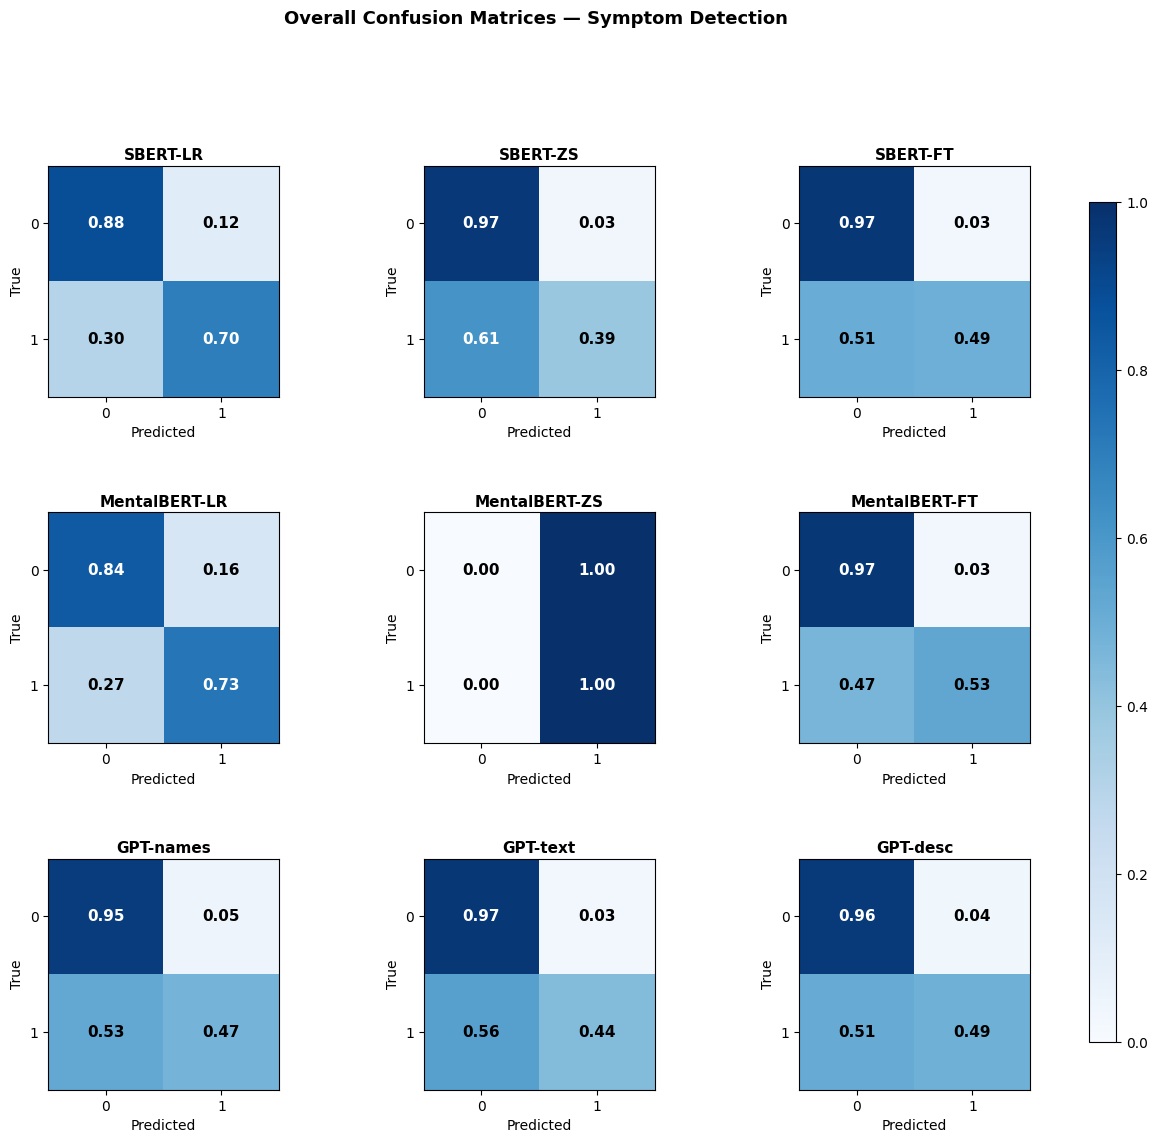

Saved → confusion_matrices_overall.png
Saved → confusion_matrices_symptom_level/cm_symptom_SBERT-LR.png
Saved → confusion_matrices_symptom_level/cm_symptom_SBERT-ZS.png
Saved → confusion_matrices_symptom_level/cm_symptom_SBERT-FT.png
Saved → confusion_matrices_symptom_level/cm_symptom_MentalBERT-LR.png
Saved → confusion_matrices_symptom_level/cm_symptom_MentalBERT-ZS.png
Saved → confusion_matrices_symptom_level/cm_symptom_MentalBERT-FT.png
Saved → confusion_matrices_symptom_level/cm_symptom_GPT-names.png
Saved → confusion_matrices_symptom_level/cm_symptom_GPT-text.png
Saved → confusion_matrices_symptom_level/cm_symptom_GPT-desc.png


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from sklearn.metrics import confusion_matrix

SYMPTOMS = {
    1: "Sadness", 2: "Pessimism", 3: "Past Failure", 4: "Loss of Pleasure",
    5: "Guilty Feelings", 6: "Punishment Feelings", 7: "Self-Dislike",
    8: "Self-Criticalness", 9: "Suicidal Thoughts or Wishes", 10: "Crying",
    11: "Agitation", 12: "Loss of Interest", 13: "Indecisiveness",
    14: "Worthlessness", 15: "Loss of Energy", 16: "Changes in Sleeping Pattern",
    17: "Irritability", 18: "Changes in Appetite", 19: "Concentration Difficulty",
    20: "Tiredness or Fatigue", 21: "Loss of Interest in Sex",
}
SYMPTOM_COLS = [f"{i}. {SYMPTOMS[i]}" for i in range(1, 22)]
PRED_COLS    = [f"pred_label_{i}" for i in range(1, 22)]

TEST_ONLY_CSVS = {
    "SBERT-LR":      "sbert_lr_preds.csv",
    "SBERT-ZS":      "sbert_zs_preds.csv",
    "SBERT-FT":      "sbert_ft_preds.csv",
    "MentalBERT-LR": "mentalbert_lr_preds.csv",
    "MentalBERT-ZS": "mentalbert_zs_preds.csv",
    "MentalBERT-FT": "mentalbert_ft_preds.csv",
}
FULL_DF_CSVS = {
    "GPT-names": "bdi_rel_pred_names.csv",
    "GPT-text":  "bdi_rel_pred_text.csv",
    "GPT-desc":  "bdi_rel_pred_desc.csv",
}

test_idx = np.load("test_idx.npy")

def load_test_rows(model_name, csv_path):
    """Return (y_true, y_pred) arrays for the test set."""
    df = pd.read_csv(csv_path)
    if model_name in FULL_DF_CSVS.values() or csv_path in FULL_DF_CSVS.values():
        df = df.iloc[test_idx].reset_index(drop=True)
    # else: CSV already contains only test rows — use as-is
    y_true = df[SYMPTOM_COLS].values.astype(int)
    y_pred = df[PRED_COLS].values.astype(int)
    return y_true, y_pred

# Merge both dicts, keep only existing files
ALL_MODELS = {**TEST_ONLY_CSVS, **FULL_DF_CSVS}
MODELS = {k: v for k, v in ALL_MODELS.items() if os.path.exists(v)}
print(f"Using {len(MODELS)} models: {list(MODELS.keys())}")

def plot_cm_ax(ax, cm_norm, title, fontsize=9):
    ax.imshow(cm_norm, vmin=0, vmax=1, cmap="Blues")
    for r in range(2):
        for c in range(2):
            color = "white" if cm_norm[r, c] > 0.6 else "black"
            ax.text(c, r, f"{cm_norm[r,c]:.2f}",
                    ha="center", va="center", fontsize=fontsize, color=color, fontweight="bold")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["0", "1"]); ax.set_yticklabels(["0", "1"])
    ax.set_xlabel("Predicted", fontsize=fontsize - 1)
    ax.set_ylabel("True",      fontsize=fontsize - 1)
    ax.set_title(title, fontsize=fontsize, fontweight="bold", pad=4)

def safe_cm_norm(y_t, y_p):
    cm = confusion_matrix(y_t, y_p, labels=[0, 1])
    row_sums = cm.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    return cm.astype(float) / row_sums


n_models = len(MODELS)
ncols = min(3, n_models)
nrows = int(np.ceil(n_models / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 4 * nrows))
axes = np.array(axes).reshape(-1)

for idx, (model_name, csv_path) in enumerate(MODELS.items()):
    y_true, y_pred = load_test_rows(model_name, csv_path)
    cm_norm = safe_cm_norm(y_true.ravel(), y_pred.ravel())
    plot_cm_ax(axes[idx], cm_norm, model_name, fontsize=11)

for j in range(n_models, len(axes)):
    axes[j].set_visible(False)

fig.subplots_adjust(right=0.88, hspace=0.5, wspace=0.4)
cbar_ax = fig.add_axes([0.91, 0.15, 0.02, 0.7])
sm = plt.cm.ScalarMappable(cmap="Blues", norm=plt.Normalize(0, 1))
sm.set_array([])
fig.colorbar(sm, cax=cbar_ax)
fig.suptitle("Overall Confusion Matrices — Symptom Detection",
             fontsize=13, fontweight="bold", y=1.01)

plt.savefig("confusion_matrices_overall.png", bbox_inches="tight", dpi=500)
plt.show()
print("Saved → confusion_matrices_overall.png")


os.makedirs("confusion_matrices_symptom_level", exist_ok=True)

for model_name, csv_path in MODELS.items():
    y_true, y_pred = load_test_rows(model_name, csv_path)

    fig, axes = plt.subplots(3, 7, figsize=(3.5 * 7, 4 * 3))
    axes_flat = axes.ravel()

    for j in range(21):
        cm_norm = safe_cm_norm(y_true[:, j], y_pred[:, j])
        plot_cm_ax(axes_flat[j], cm_norm,
                   f"{j+1}. {SYMPTOMS[j+1]}", fontsize=7.5)

    fig.subplots_adjust(right=0.88, hspace=0.65, wspace=0.45)
    cbar_ax = fig.add_axes([0.91, 0.15, 0.015, 0.7])
    sm = plt.cm.ScalarMappable(cmap="Blues", norm=plt.Normalize(0, 1))
    sm.set_array([])
    fig.colorbar(sm, cax=cbar_ax)
    fig.suptitle(f"Symptom-Level Confusion Matrices — {model_name}",
                 fontsize=14, fontweight="bold", y=1.01)

    out_path = f"confusion_matrices_symptom_level/cm_symptom_{model_name}.png"
    plt.savefig(out_path, bbox_inches="tight", dpi=500)
    plt.close()
    print(f"Saved → {out_path}")